# Exploración de viajes históricos de Ecobici

Se desarrolla este notebook para validar con evidencia los problemas de calidad del README (sección 5) y obtener patrones de demanda para el modelo.

In [27]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw_trips"
files = sorted(RAW.glob("*.csv"))
print(f"{len(files)} archivo(s):", [f.name for f in files])
assert files, f"No hay CSV en {RAW}. Descarga al menos uno."


2 archivo(s): ['public_data_web_2026-09.csv', 'public_data_web_2026-10.csv']


## 1. Carga y normalización de columnas

Se normalizan los nombres de las columnas porque suelen cambiar entre años. Se hace esto para tener un esquema ínico

In [28]:
COLMAP = {
    "genero_usuario": "user_gender",
    "edad_usuario": "user_age",
    "bici": "bike_id",
    "ciclo_estacion_retiro": "station_out",
    "ciclo_estacionarribo": "station_in",
    "ciclo_estacion_arribo": "station_in",
    "fecha_retiro": "date_out",
    "hora_retiro": "time_out",
    "fecha_arribo": "date_in",
    "hora_arribo": "time_in",
}

def load(path):
    # dtype=str para no perder ceros a la izquierda en IDs de estación (p. ej. "003")
    try:
        df = pd.read_csv(path, dtype=str)
    except UnicodeDecodeError:
        df = pd.read_csv(path, dtype=str, encoding="latin-1")
    df.columns = [c.strip().lower() for c in df.columns]
    unknown = [c for c in df.columns if c not in COLMAP]
    if unknown:
        print(f"  {path.name}: columnas no mapeadas -> {unknown}")
    df = df.rename(columns=COLMAP)
    df["source_file"] = path.name
    return df

raw = pd.concat([load(f) for f in files], ignore_index=True)
print(f"{len(raw):,} viajes cargados")
raw.head()


3,098,318 viajes cargados


,user_gender,user_age,bike_id,station_out,date_out,time_out,station_in,date_in,time_in,source_file
0,M,30.0,6583322,028,31/08/2026,23:54:59,258,01/09/2026,00:00:03,public_data_web_2026-09.csv
1,F,33.0,4139655,030,31/08/2026,23:24:43,530,01/09/2026,00:00:04,public_data_web_2026-09.csv
2,O,32.0,6378079,139,31/08/2026,23:46:59,559,01/09/2026,00:00:35,public_data_web_2026-09.csv
3,M,35.0,6074272,365,31/08/2026,23:52:10,312,01/09/2026,00:00:44,public_data_web_2026-09.csv
4,M,30.0,4162376,412,31/08/2026,23:51:45,337,01/09/2026,00:00:55,public_data_web_2026-09.csv


## 2. Esquema y nulos

In [29]:
schema = pd.DataFrame({
    "tipo_original": raw.dtypes.astype(str),
    "nulos": raw.isna().sum(),
    "pct_nulos": (raw.isna().mean() * 100).round(2),
    "valores_unicos": raw.nunique(),
    "ejemplo": raw.iloc[0],
})
schema


,tipo_original,nulos,pct_nulos,valores_unicos,ejemplo
user_gender,str,0,0.0,4,M
user_age,str,59,0.0,77,30.0
bike_id,str,0,0.0,6584,6583322
station_out,str,0,0.0,676,028
date_out,str,0,0.0,71,31/08/2026
time_out,str,0,0.0,70157,23:54:59
station_in,str,0,0.0,676,258
date_in,str,0,0.0,61,01/09/2026
time_in,str,0,0.0,72293,00:00:03
source_file,str,0,0.0,2,public_data_web_2026-09.csv


## 3. Fechas y duración

Fechas en formato `dd/mm/aaaa`, hora local de CDMX. Contamos cuántas no se pueden interpretar.

In [30]:
def parse_ts(d, t):
    s = d.str.strip() + " " + t.str.strip()
    ts = pd.to_datetime(s, format="%d/%m/%Y %H:%M:%S", errors="coerce")
    miss = ts.isna() & s.notna()
    if miss.any():  # respaldo para formatos distintos (otros años)
        ts[miss] = pd.to_datetime(s[miss], dayfirst=True, errors="coerce", format="mixed")
    return ts

df = raw.copy()
df["ts_out"] = parse_ts(df["date_out"], df["time_out"])
df["ts_in"] = parse_ts(df["date_in"], df["time_in"])
df["duration_min"] = (df["ts_in"] - df["ts_out"]).dt.total_seconds() / 60
df["user_age"] = pd.to_numeric(df["user_age"], errors="coerce")
for c in ["station_out", "station_in"]:
    df[c] = df[c].str.strip()

print("Fechas de retiro no interpretables:", df["ts_out"].isna().sum())
print("Fechas de arribo no interpretables:", df["ts_in"].isna().sum())
print("Rango:", df["ts_out"].min(), "a", df["ts_out"].max())
df["duration_min"].describe(percentiles=[.01, .05, .5, .95, .99]).round(1)


Fechas de retiro no interpretables: 0
Fechas de arribo no interpretables: 0
Rango: 2026-02-10 08:46:10 a 2026-10-31 23:56:08


count    3098318.0
mean          15.9
std          312.0
min            0.3
1%             2.2
5%             3.6
50%           12.0
95%           37.3
99%           52.6
max       351438.6
Name: duration_min, dtype: float64

## 4. Reglas de calidad sobre viajes

In [31]:
dq = pd.DataFrame(index=df.index)
dq["fecha_invalida"] = df["ts_out"].isna() | df["ts_in"].isna()
dq["arribo_antes_de_retiro"] = df["duration_min"] < 0
dq["viaje_menor_1min"] = df["duration_min"].between(0, 1, inclusive="left")
dq["viaje_mayor_24h"] = df["duration_min"] > 24 * 60
dq["edad_nula"] = df["user_age"].isna()
dq["edad_atipica"] = df["user_age"].notna() & ~df["user_age"].between(16, 85)
dq["genero_no_reportado"] = df["user_gender"].eq("?")
dq["genero_fuera_catalogo"] = ~df["user_gender"].isin(["M", "F", "O", "?"])
dq["fecha_fuera_de_periodo"] = df["ts_out"] < pd.Timestamp("2026-08-31")
dq["misma_estacion_menor_2min"] = (df["station_out"] == df["station_in"]) & (df["duration_min"] < 2)
dq["duplicado"] = df.duplicated(subset=["bike_id", "ts_out", "station_out"], keep="first")

dq_summary = pd.DataFrame({"viajes": dq.sum(), "pct": (dq.mean() * 100).round(3)}).sort_values("viajes", ascending=False)
criticas = dq.columns.drop("genero_no_reportado")  # un género faltante no invalida el viaje
df["dq_ok"] = ~dq[criticas].any(axis=1)
print(f"Viajes que pasan todas las reglas: {df['dq_ok'].mean():.2%}")
dq_summary


Viajes que pasan todas las reglas: 99.98%


,viajes,pct
genero_no_reportado,78631,2.538
viaje_menor_1min,447,0.014
edad_atipica,106,0.003
viaje_mayor_24h,61,0.002
edad_nula,59,0.002
fecha_fuera_de_periodo,10,0.000
fecha_invalida,0,0.000
arribo_antes_de_retiro,0,0.000
genero_fuera_catalogo,0,0.000
misma_estacion_menor_2min,0,0.000


**Interpretaciones:**
- Viaje menor a 1 min o misma estación en menos de 2 min: suele ser alguien que sacó la bici, la notó dañada y la regresó. No es demanda real.
- Viaje mayor a 24 h: bici perdida, robada o no anclada correctamente.
- Edad atípica: puede ser un error de captura o registro falso (pero para este proyecto solo usaremos rangos de edades)

## 5. ¿Los IDs del CSV coinciden con el feed en vivo?

Esto es importante por que necesitamos unir viajes históricos con los snpshots. Usamos el catálogo que ya guardó `run_snapshot`.

In [32]:
cat_files = sorted((ROOT / "data" / "silver" / "dim_station").rglob("*.parquet"))
if not cat_files:
    print("Aún no hay catálogo. Corre `python -m ecobici.run_snapshot` primero.")
else:
    cat = pd.read_parquet(cat_files[-1])
    ids_csv = set(df["station_out"].dropna()) | set(df["station_in"].dropna())
    norm = lambda s: s.lstrip("0") or "0"
    keys = {
        "station_id": set(cat["station_id"].dropna()),
        "short_name": set(cat["short_name"].dropna()),
        "short_name sin ceros": {norm(x) for x in cat["short_name"].dropna()},
    }
    ids_norm = {norm(x) for x in ids_csv}
    for k, v in keys.items():
        base = ids_norm if "sin ceros" in k else ids_csv
        print(f"Coincidencia CSV vs {k:<22}: {len(base & v) / len(base):.1%}  ({len(base & v)} de {len(base)})")
    print("\nEjemplos de IDs del CSV:", sorted(ids_csv)[:10])
    print("Ejemplos de short_name del feed:", sorted(keys["short_name"])[:10])


Coincidencia CSV vs station_id            : 79.4%  (537 de 676)
Coincidencia CSV vs short_name            : 100.0%  (676 de 676)
Coincidencia CSV vs short_name sin ceros  : 100.0%  (676 de 676)

Ejemplos de IDs del CSV: ['001', '002', '003', '004', '005', '006', '007', '008', '009', '010']
Ejemplos de short_name del feed: ['001', '002', '003', '004', '005', '006', '007', '008', '009', '010']


## 6. Patrones de demanda

/var/folders/t1/bb2mgfbx65b_pysz1lsnz8rc0000gn/T/ipykernel_30156/1659059937.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  ok["dia"] = ok["ts_out"].dt.dayofweek


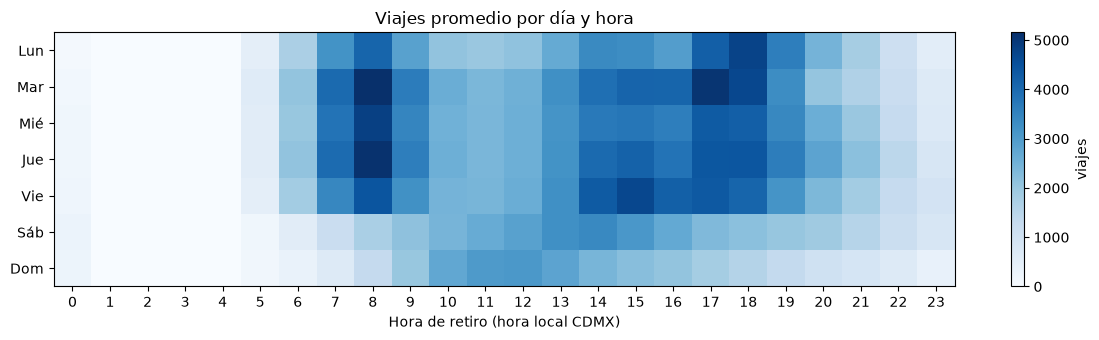

hora
0      12959
5      28122
6      95891
7     182326
8     239851
9     188404
10    156157
11    155060
12    164341
13    194274
14    225704
15    228082
16    210954
17    237815
18    233512
19    184119
20    136587
21    106662
22     72752
23     44073
Name: count, dtype: int64

In [33]:
ok = df[df["dq_ok"]].copy()
ok["hora"] = ok["ts_out"].dt.hour
ok["dia"] = ok["ts_out"].dt.dayofweek
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

heat = (ok.pivot_table(index="dia", columns="hora", values="bike_id", aggfunc="count")
          .reindex(index=range(7), columns=range(24))   # fuerza las 24 horas, aunque alguna no tenga viajes
          .fillna(0))
n_semanas = max(ok["ts_out"].dt.isocalendar().week.nunique(), 1)

fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(heat / n_semanas, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), dias)
ax.set_xticks(range(24), heat.columns)
ax.set_xlabel("Hora de retiro (hora local CDMX)")
ax.set_title("Viajes promedio por día y hora")
fig.colorbar(im, ax=ax, label="viajes")
plt.tight_layout()
plt.show()

# Verificación: viajes por hora sin graficar
ok["hora"].value_counts().sort_index()

Este mapa de calor muestra en qué días y horarios se concentra la demanda.

- Horario de operación: no hay viajes entre la 1:00 y las 4:59 porque el sistema está cerrado. La demanda arranca a las 5:00 y cae después de las 21:00.
- Pico matutino (entre semana): de 7:00 a 9:00, con el máximo a las 8:00. Es el más concentrado del día y coincide con la entrada al trabajo y a la escuela. Es más intenso de martes a jueves.
- Pico vespertino (entre semana): de 17:00 a 18:00. Es el regreso a casa y dura más que el matutino.
- Mediodía: entre 13:00 y 16:00 la demanda se mantiene alta. Los viernes este bloque es el más fuerte de la semana, lo que sugiere salidas más tempranas.
- Fines de semana: no hay picos de traslado al trabajo, entonces la demanda se concentra entre 10:00 y 15:00 y es más baja y distribuida.

**Validación:** en una primera versión aparecían picos a las 3:00–5:00 y nada después de las 19:00. Se revisó y era un error de visualización: las horas sin viajes no se incluían en el eje, lo que recorría las etiquetas. Se corrigió forzando las 24 horas y se confirmó con el conteo de viajes por hora.

Implicaciones para el modelo y el negocio:
- Las ventanas críticas de rebalanceo son antes de las 7:00 y antes de las 17:00.
- Entre semana y fin de semana se comportan distinto: el día de la semana y si es festivo tienen que ser variables del modelo.
- Las horas de 1:00 a 4:59 no se predicen (el sistema está cerrado), y esto simplifica el modelo y sirve como ventana natural para reentrenar y rebalancear.

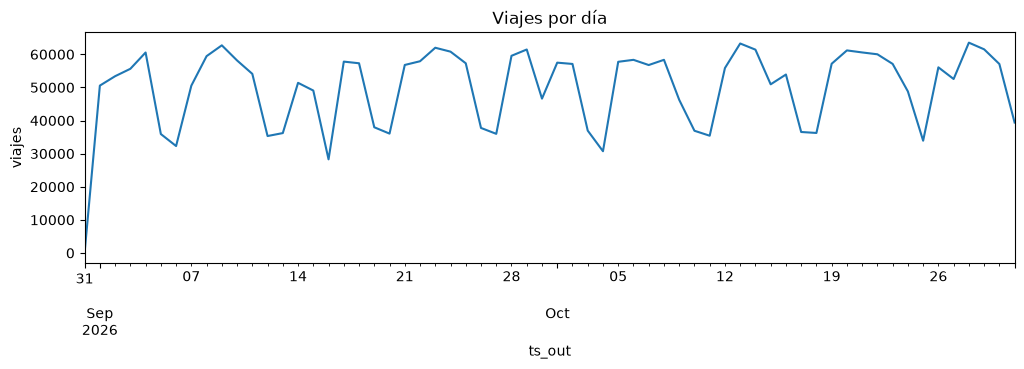

In [34]:
daily = ok.set_index("ts_out").resample("D").size()
ax = daily.plot(figsize=(12, 3), title="Viajes por día")
ax.set_ylabel("viajes")
plt.show()


En esta gráfica observamos el volumen total de viajes diarios en septiembre y octubre 2026
- Los días de mayor demanda tienen aprox entre 55 mil y 60 mul viajes
- Los días de menor demanda tienen aprox entre 30 mil y 35 mil viajes
- Hay caídas periódicas cada 7 días (probablemente son los fines de semana)
- No se ve una tendencia de crecimiento o disminución en estos meses

En general vemos que la demanda de viajes en ecobici tiene una estacionalidad semanal marcada, porque el número de viajes cambia de forma recurrente dependiendo del día de la semana --> el día de la semana va a ser relevante para explicar y predecir el número de viajes.

## 7. Balance neto por estación (insumo para rebalanceo)

`neto = arribos − retiros`. Negativo: la estación se vacía. Positivo: se llena. Estas estaciones son las que el modelo debe predecir mejor.

In [35]:
ok["periodo"] = pd.cut(ok["hora"], bins=[-1, 5, 10, 15, 20, 23],
                        labels=["madrugada", "mañana", "mediodía", "tarde", "noche"])
out_ = ok.groupby(["station_out", "periodo"], observed=True).size().rename("retiros")
in_ = ok.assign(periodo_in=ok["periodo"]).groupby(["station_in", "periodo_in"], observed=True).size().rename("arribos")
in_.index.names = ["station_out", "periodo"]
bal = pd.concat([out_, in_], axis=1).fillna(0)
bal["neto"] = bal["arribos"] - bal["retiros"]
manana = bal.xs("mañana", level="periodo").sort_values("neto")

print("Estaciones que más se VACÍAN en la mañana:")
display(manana.head(10))
print("Estaciones que más se LLENAN en la mañana:")
display(manana.tail(10).iloc[::-1])


Estaciones que más se VACÍAN en la mañana:


,retiros,arribos,neto
station_out,,,
271-272,11409,1490.0,-9919.0
266-267,6779,1574.0,-5205.0
273-274,5394,708.0,-4686.0
208,5683,2489.0,-3194.0
211,3762,1243.0,-2519.0
492,3783,1329.0,-2454.0
548,5753,3490.0,-2263.0
268-269,2863,672.0,-2191.0
237-238,4956,2837.0,-2119.0


Estaciones que más se LLENAN en la mañana:


,retiros,arribos,neto
station_out,,,
014,2482,7114.0,4632.0
018,3014,6389.0,3375.0
242,1580,4792.0,3212.0
217,1152,4312.0,3160.0
027,2941,5837.0,2896.0
474,1621,4449.0,2828.0
302,1450,3974.0,2524.0
017,1584,3968.0,2384.0
235-236,1135,3477.0,2342.0


In [36]:
cat_names = cat.set_index("short_name")["name"]
manana.assign(nombre=manana.index.map(cat_names)).sort_values("neto").head(10)

,retiros,arribos,neto,nombre
station_out,,,,
271-272,11409,1490.0,-9919.0,CE-271-272 Jesús García - Carlos J. Meneses
266-267,6779,1574.0,-5205.0,CE-266-267 Jesús García - Carlos J. Meneses
273-274,5394,708.0,-4686.0,CE-273-274 Luis Donaldo Colosio - Av. Jesús Ga...
208,5683,2489.0,-3194.0,CE-208 Hesiodo-Lamartine
211,3762,1243.0,-2519.0,CE-211 Isaac Newton-Horacio
492,3783,1329.0,-2454.0,CE-492 Lago Cuitzeo - Felipe Carrillo Puerto
548,5753,3490.0,-2263.0,CE-548 Dr. Mariano Azuela - Jose Antonio Alzate
268-269,2863,672.0,-2191.0,CE-268-269 Luis Donaldo Colosio - Av. Jesús Ga...
237-238,4956,2837.0,-2119.0,CE-237-238 Andrés Bello-George Eliot


In [37]:
cat_names = cat.set_index("short_name")["name"]
manana.assign(nombre=manana.index.map(cat_names)).sort_values("neto").tail(10)

,retiros,arribos,neto,nombre
station_out,,,,
197,918,3150.0,2232.0,CE-197 Presa Falcón - Miguel De Cervantes Saav...
235-236,1135,3477.0,2342.0,CE-235-236 Campos Elíseos-Moliere
017,1584,3968.0,2384.0,CE-017 Reforma - Río Tiber
302,1450,3974.0,2524.0,CE-302 Luz Saviñón-Magdalena
474,1621,4449.0,2828.0,CE-474 Bahía de San Hipólito-Bahía del Espírit...
027,2941,5837.0,2896.0,CE-027 Reforma- Havre
217,1152,4312.0,3160.0,CE-217 Euler-Horacio
242,1580,4792.0,3212.0,CE-242 Pról. Moliere-Miguel de Cervantes Saavedra
018,3014,6389.0,3375.0,CE-018 Reforma - Río Rhin


## 8. Perfil de usuarios (solo agregado, edad en rangos)

In [38]:
ok["rango_edad"] = pd.cut(ok["user_age"], bins=[15, 24, 34, 44, 54, 64, 120],
                          labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"])
perfil = pd.crosstab(ok["rango_edad"], ok["user_gender"], normalize=True).mul(100).round(1)
perfil


user_gender,?,F,M,O
rango_edad,,,,
16-24,0.4,3.4,7.7,0.2
25-34,1.4,14.1,29.1,0.9
35-44,0.5,6.8,19.2,0.5
45-54,0.1,2.4,8.0,0.1
55-64,0.1,0.9,3.1,0.0
65+,0.0,0.2,0.8,0.0


## 9. Resumen para el README

In [39]:
resumen = {
    "archivos": len(files),
    "viajes_totales": len(df),
    "periodo": f"{df['ts_out'].min():%Y-%m-%d} a {df['ts_out'].max():%Y-%m-%d}",
    "pct_viajes_validos": f"{df['dq_ok'].mean():.2%}",
    "duracion_mediana_min": round(ok["duration_min"].median(), 1),
    "estaciones_distintas": ok["station_out"].nunique(),
    "hora_pico": int(ok["hora"].mode()[0]),
    "tamano_mb_csv": round(sum(f.stat().st_size for f in files) / 1e6, 1),
}
for k, v in resumen.items():
    print(f"- {k}: {v}")
print("\nProblemas de calidad (top):")
try:
    print(dq_summary.head(6).to_markdown())
except ImportError:  # to_markdown necesita el paquete tabulate
    print(dq_summary.head(6))


- archivos: 2
- viajes_totales: 3098318
- periodo: 2026-02-10 a 2026-10-31
- pct_viajes_validos: 99.98%
- duracion_mediana_min: 12.0
- estaciones_distintas: 676
- hora_pico: 8
- tamano_mb_csv: 199.3

Problemas de calidad (top):
                        viajes    pct
genero_no_reportado      78631  2.538
viaje_menor_1min           447  0.014
edad_atipica               106  0.003
viaje_mayor_24h             61  0.002
edad_nula                   59  0.002
fecha_fuera_de_periodo      10  0.000


## Validaciones extras

In [40]:
df["ts_out"].dt.to_period("M").value_counts().sort_index()

ts_out
2026-02          2
2026-05          1
2026-06          2
2026-08         98
2026-09    1498978
2026-10    1599237
Freq: M, Name: count, dtype: int64

In [41]:
raw["user_gender"].value_counts(dropna=False)

user_gender
M    2104304
F     860766
?      78631
O      54617
Name: count, dtype: int64

In [42]:
df[df["ts_out"] < "2026-08-01"][["ts_out", "ts_in", "duration_min", "station_out", "source_file"]]

,ts_out,ts_in,duration_min,station_out,source_file
419203,2026-02-10 08:46:10,2026-09-09 11:43:23,304017.216667,309,public_data_web_2026-09.csv
661649,2026-06-29 19:07:35,2026-09-14 11:25:01,110417.433333,030,public_data_web_2026-09.csv
1390570,2026-05-20 15:36:58,2026-09-28 23:24:37,189107.650000,145,public_data_web_2026-09.csv
2308876,2026-02-14 17:52:04,2026-10-16 19:10:40,351438.600000,218,public_data_web_2026-10.csv
2591146,2026-06-24 15:07:09,2026-10-22 13:21:44,172694.583333,219,public_data_web_2026-10.csv
